In [1]:
!pip install xgboost


In [2]:
!pip install -U scikit-learn
!pip install -U imbalanced-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 103.7 MB/s eta 0:00:0000:010:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
bigframes 1.36.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.


In [3]:
!pip install -U scikit-learn imbalanced-learn

Trying all combinations with GPU enabled...



/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [04:51:20] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


Learning Rate: 0.01, N_Estimators: 100, Max_Depth: 7 --> Accuracy: 0.7377
Learning Rate: 0.01, N_Estimators: 100, Max_Depth: 10 --> Accuracy: 0.7535
Learning Rate: 0.01, N_Estimators: 100, Max_Depth: 12 --> Accuracy: 0.7662
Learning Rate: 0.01, N_Estimators: 100, Max_Depth: 15 --> Accuracy: 0.7888
Learning Rate: 0.01, N_Estimators: 100, Max_Depth: 20 --> Accuracy: 0.8200
Learning Rate: 0.01, N_Estimators: 200, Max_Depth: 7 --> Accuracy: 0.7490
Learning Rate: 0.01, N_Estimators: 200, Max_Depth: 10 --> Accuracy: 0.7649
Learning Rate: 0.01, N_Estimators: 200, Max_Depth: 12 --> Accuracy: 0.7773
Learning Rate: 0.01, N_Estimators: 200, Max_Depth: 15 --> Accuracy: 0.7993
Learning Rate: 0.01, N_Estimators: 200, Max_Depth: 20 --> Accuracy: 0.8336
Learning Rate: 0.01, N_Estimators: 500, Max_Depth: 7 --> Accuracy: 0.7705
Learning Rate: 0.01, N_Estimators: 500, Max_Depth: 10 --> Accuracy: 0.7868
Learning Rate: 0.01, N_Estimators: 500, Max_Depth: 12 --> Accuracy: 0.8005
Learning Rate: 0.01, N_Estim

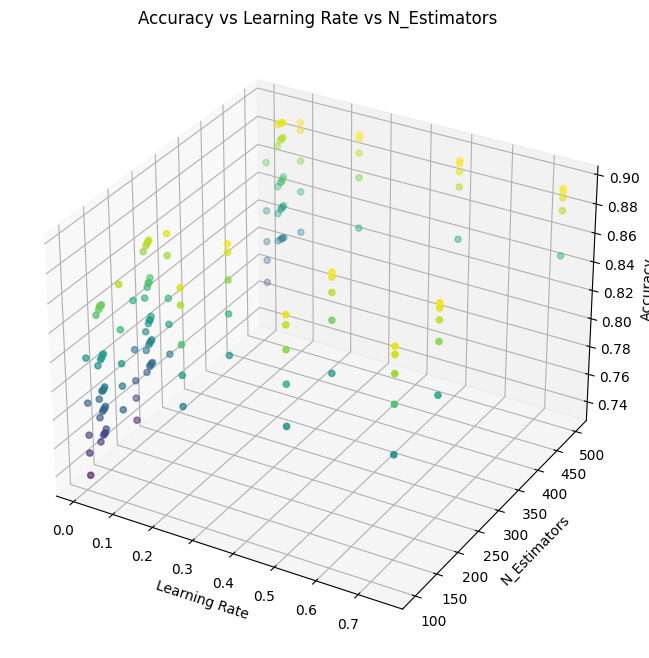

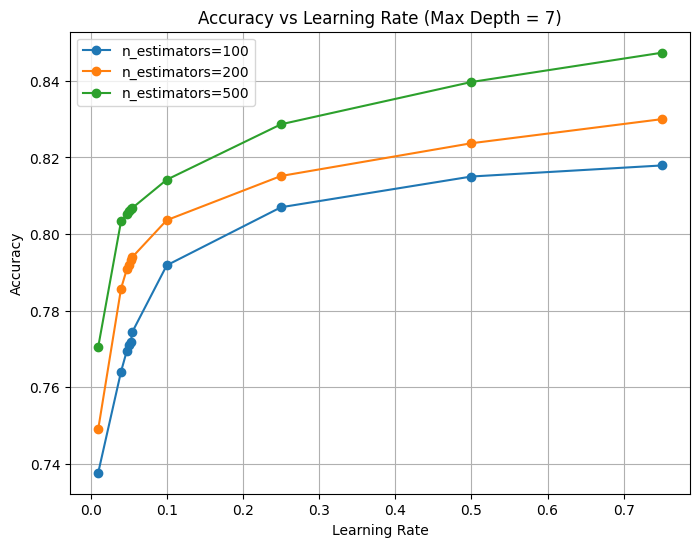

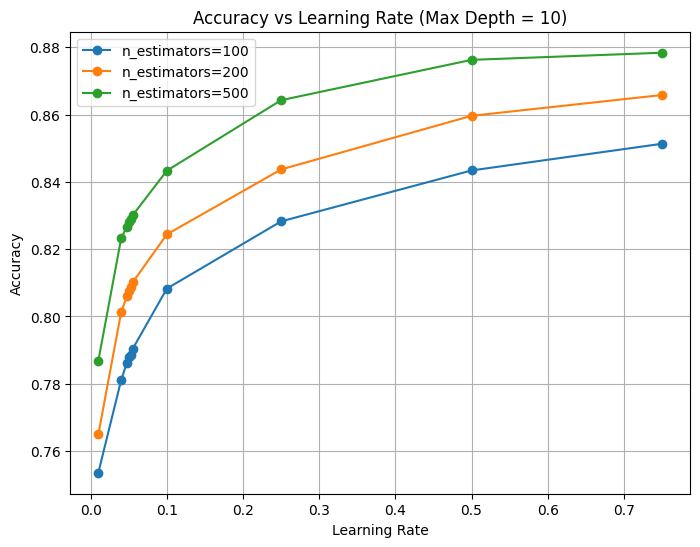

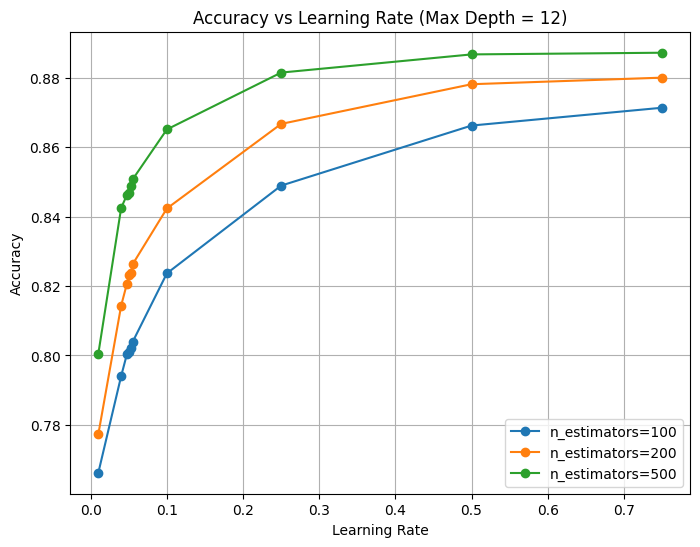

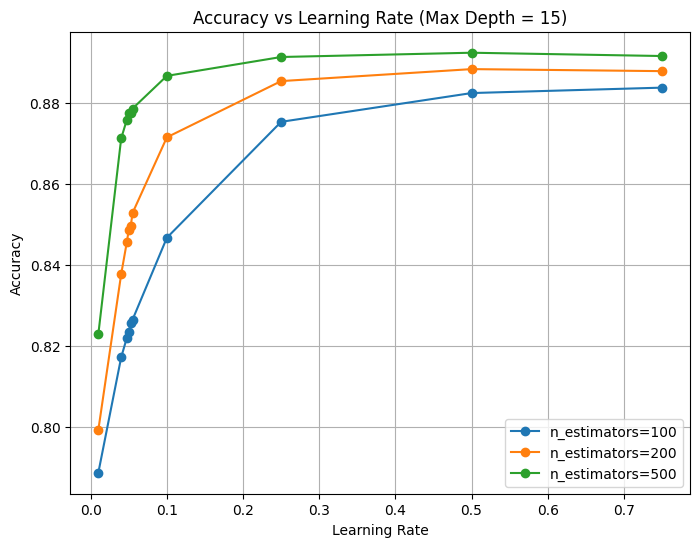

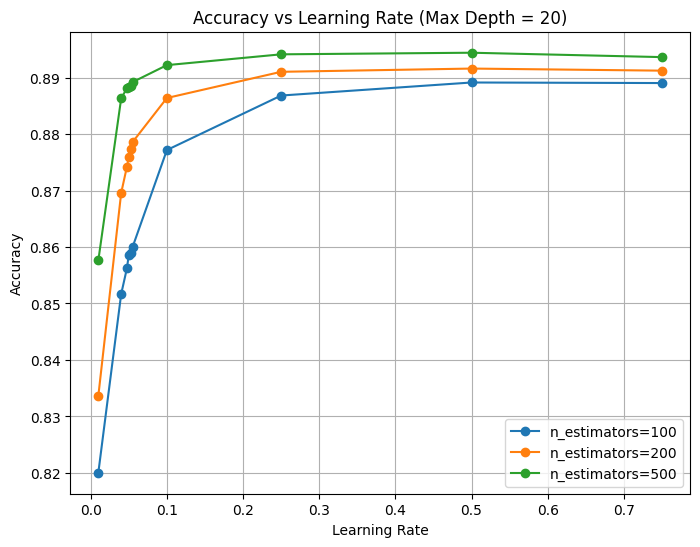

In [4]:
# Import necessary libraries
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from itertools import product
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Import SMOTE
from imblearn.over_sampling import SMOTE

# Load the dataset
data = pd.read_csv('/kaggle/input/synthetic-handover-data/synthetic_handover_data (2).csv')

# Define feature columns and target variable
feature_cols = ['DL', 'UL', 'RSSI', 'rsrq', 'rsrp', 'nrxsrp', 'nrxsrq', 'snr', 'CQI', 'speed']
target_col = 'Handover'

# Features and target
X = data[feature_cols]
y = data[target_col]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Define parameter grid
learning_rates = [0.01, 0.04, 0.0475, 0.05, 0.0525, 0.055, 0.1, 0.25, 0.5, 0.75]
n_estimators_list = [100, 200, 500]
max_depths = [7, 10,12,15,20]

# Variables to store best results
best_accuracy = 0
best_params = {}
results = []

print("Trying all combinations with GPU enabled...\n")

# Try all combinations
for lr, n_est, depth in product(learning_rates, n_estimators_list, max_depths):
    model = XGBClassifier(
        tree_method="hist",  # GPU acceleration
        device="cuda",  # GPU predictor
        learning_rate=lr,
        n_estimators=n_est,
        max_depth=depth,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    print(f"Learning Rate: {lr}, N_Estimators: {n_est}, Max_Depth: {depth} --> Accuracy: {acc:.4f}")
    
    results.append({'learning_rate': lr, 'n_estimators': n_est, 'max_depth': depth, 'accuracy': acc})
    
    if acc > best_accuracy:
        best_accuracy = acc
        best_params = {'learning_rate': lr, 'n_estimators': n_est, 'max_depth': depth}

# Results
results_df = pd.DataFrame(results)

# Best Model
print("\nBest Combination:")
print(f"Learning Rate: {best_params['learning_rate']}, N_Estimators: {best_params['n_estimators']}, Max_Depth: {best_params['max_depth']}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# 3D Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    results_df['learning_rate'],
    results_df['n_estimators'],
    results_df['accuracy'],
    c=results_df['accuracy'],
    cmap='viridis',
    marker='o'
)

ax.set_xlabel('Learning Rate')
ax.set_ylabel('N_Estimators')
ax.set_zlabel('Accuracy')
ax.set_title('Accuracy vs Learning Rate vs N_Estimators')
plt.show()

# 2D Plot for fixed max_depths
for depth in max_depths:
    subset = results_df[results_df['max_depth'] == depth]
    plt.figure(figsize=(8, 6))
    for n_est in n_estimators_list:
        subsub = subset[subset['n_estimators'] == n_est]
        plt.plot(subsub['learning_rate'], subsub['accuracy'], marker='o', label=f'n_estimators={n_est}')
    
    plt.xlabel('Learning Rate')
    plt.ylabel('Accuracy')
    plt.title(f'Accuracy vs Learning Rate (Max Depth = {depth})')
    plt.legend()
    plt.grid(True)
    plt.show()


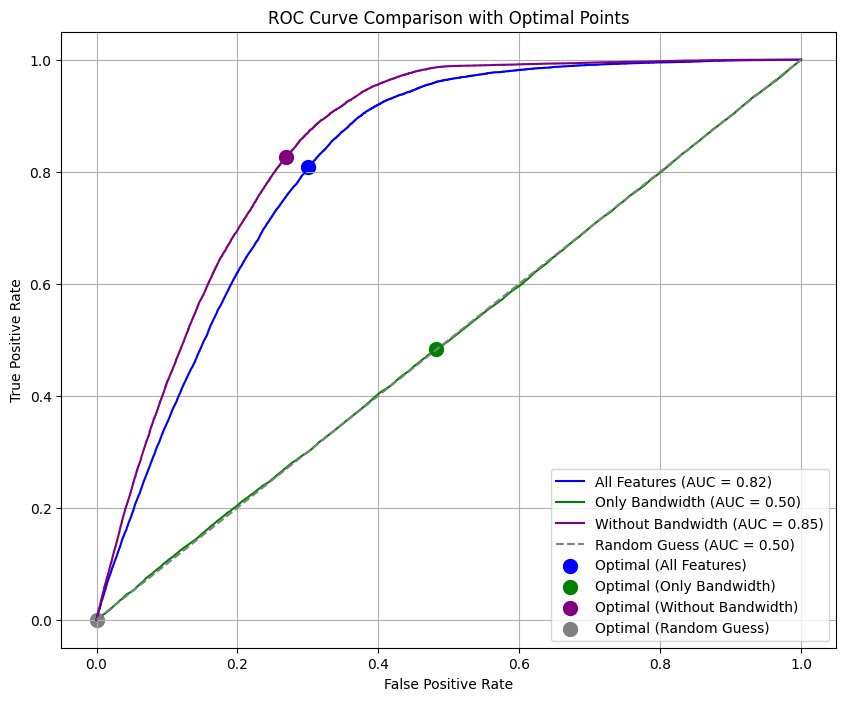

In [14]:
# Ensure the models are fit and ROC curve values are computed:
# Assuming 'model_band' for only bandwidth, 'model_no_band' for excluding bandwidth, and 'dummy' for random guess

# ROC for all features (already defined as 'model_all')
fpr_all, tpr_all, _ = roc_curve(y_test, y_score_all)
roc_auc_all = auc(fpr_all, tpr_all)

# Fit model using only Bandwidth (e.g., 'DL' feature)
X_band = X[['DL']]  # Only 'DL' column for Bandwidth
X_band_train, X_band_test, y_band_train, y_band_test = train_test_split(X_band, y, test_size=0.3, random_state=42)
X_band_train, y_band_train = smote.fit_resample(X_band_train, y_band_train)

model_band = XGBClassifier(
    tree_method="hist",
    device="cuda",
    learning_rate=0.1,
    n_estimators=100,
    max_depth=5,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
model_band.fit(X_band_train, y_band_train)
y_score_band = model_band.predict_proba(X_band_test)[:, 1]
fpr_band, tpr_band, _ = roc_curve(y_band_test, y_score_band)
roc_auc_band = auc(fpr_band, tpr_band)

# Fit model excluding 'DL' feature (without bandwidth)
X_no_band = X.drop(columns=['DL'])  # Remove 'DL' column
X_no_band_train, X_no_band_test, y_no_band_train, y_no_band_test = train_test_split(X_no_band, y, test_size=0.3, random_state=42)
X_no_band_train, y_no_band_train = smote.fit_resample(X_no_band_train, y_no_band_train)

model_no_band = XGBClassifier(
    tree_method="hist",
    device="cuda",
    learning_rate=0.1,
    n_estimators=100,
    max_depth=5,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
model_no_band.fit(X_no_band_train, y_no_band_train)
y_score_no_band = model_no_band.predict_proba(X_no_band_test)[:, 1]
fpr_no_band, tpr_no_band, _ = roc_curve(y_no_band_test, y_score_no_band)
roc_auc_no_band = auc(fpr_no_band, tpr_no_band)

# Random guess classifier
dummy = DummyClassifier(strategy="uniform", random_state=42)
dummy.fit(X_train, y_train)
y_score_dummy = dummy.predict_proba(X_test)[:, 1]
fpr_random, tpr_random, _ = roc_curve(y_test, y_score_dummy)
roc_auc_random = auc(fpr_random, tpr_random)

# Function to calculate the Euclidean distance to the top-left corner (0, 1)
def optimal_point(fpr, tpr):
    # Calculate the Euclidean distance for each point on the ROC curve
    distance = np.sqrt(fpr**2 + (1 - tpr)**2)
    # Find the index of the optimal point (min distance)
    optimal_idx = np.argmin(distance)
    # Return the FPR and TPR of the optimal point
    return fpr[optimal_idx], tpr[optimal_idx]

# Get the optimal points for all the models
optimal_fpr_all, optimal_tpr_all = optimal_point(fpr_all, tpr_all)
optimal_fpr_band, optimal_tpr_band = optimal_point(fpr_band, tpr_band)
optimal_fpr_no_band, optimal_tpr_no_band = optimal_point(fpr_no_band, tpr_no_band)
optimal_fpr_random, optimal_tpr_random = optimal_point(fpr_random, tpr_random)

# Now plot all ROC curves with optimal points
plt.figure(figsize=(10, 8))

# Plot ROC curves for all cases
plt.plot(fpr_all, tpr_all, label=f"All Features (AUC = {roc_auc_all:.2f})", color='blue')
plt.plot(fpr_band, tpr_band, label=f"Only Bandwidth (AUC = {roc_auc_band:.2f})", color='green')
plt.plot(fpr_no_band, tpr_no_band, label=f"Without Bandwidth (AUC = {roc_auc_no_band:.2f})", color='purple')
plt.plot(fpr_random, tpr_random, label=f"Random Guess (AUC = {roc_auc_random:.2f})", linestyle='--', color='gray')

# Plot the optimal points for each model
plt.scatter(optimal_fpr_all, optimal_tpr_all, color='blue', marker='o', s=100, label='Optimal (All Features)')
plt.scatter(optimal_fpr_band, optimal_tpr_band, color='green', marker='o', s=100, label='Optimal (Only Bandwidth)')
plt.scatter(optimal_fpr_no_band, optimal_tpr_no_band, color='purple', marker='o', s=100, label='Optimal (Without Bandwidth)')
plt.scatter(optimal_fpr_random, optimal_tpr_random, color='gray', marker='o', s=100, label='Optimal (Random Guess)')

# Add labels and title
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison with Optimal Points')
plt.legend(loc='lower right')
plt.grid(True)

# Display the plot
plt.show()


In [6]:
# --- Create Accuracy Summary Table ---

# Compute average accuracy for each learning rate
avg_acc_by_lr = results_df.groupby('learning_rate')['accuracy'].mean().reset_index()

# Prepare display format
print("\nAccuracy on Validation Set with Different Learning Rates (All Features)\n")
header_1 = "| Learning Rate | " + " | ".join([f"{lr:.4g}" for lr in avg_acc_by_lr['learning_rate']]) + " |"
header_2 = "|---" + "|".join(["-------" for _ in avg_acc_by_lr['learning_rate']]) + "|"
acc_row = "| Avg Accuracy  | " + " | ".join([f"{acc:.3f}" for acc in avg_acc_by_lr['accuracy']]) + " |"

# Print markdown-style table
print(header_1)
print(header_2)
print(acc_row)



Accuracy on Validation Set with Different Learning Rates (All Features)

| Learning Rate | 0.01 | 0.04 | 0.0475 | 0.05 | 0.0525 | 0.055 | 0.1 | 0.25 | 0.5 | 0.75 |
|----------|-------|-------|-------|-------|-------|-------|-------|-------|-------|
| Avg Accuracy  | 0.789 | 0.823 | 0.828 | 0.829 | 0.830 | 0.832 | 0.845 | 0.861 | 0.868 | 0.871 |


In [7]:
# Table-1: Average Accuracy for Each Learning Rate
table1_part1 = results_df[results_df['learning_rate'].isin([0.01, 0.04, 0.0475, 0.05, 0.0525])]
table1_part2 = results_df[results_df['learning_rate'].isin([0.055, 0.1, 0.25, 0.5, 0.75])]

# Compute average accuracy for each learning rate
avg_acc_part1 = table1_part1.groupby('learning_rate')['accuracy'].mean()
avg_acc_part2 = table1_part2.groupby('learning_rate')['accuracy'].mean()

# Display as table format
print("\nTable-1: Accuracy on Validation Set with Different Learning Rates (All Features)\n")
print("Learning Rate Group 1:")
print(avg_acc_part1.to_frame(name="Average Accuracy").T)

print("\nLearning Rate Group 2:")
print(avg_acc_part2.to_frame(name="Average Accuracy").T)



Table-1: Accuracy on Validation Set with Different Learning Rates (All Features)

Learning Rate Group 1:
learning_rate       0.0100    0.0400   0.0475    0.0500   0.0525
Average Accuracy  0.788597  0.822916  0.82759  0.829075  0.82999

Learning Rate Group 2:
learning_rate        0.055     0.100     0.250     0.500     0.750
Average Accuracy  0.831509  0.845173  0.860558  0.868488  0.871112


In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(X, y, desc):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = XGBClassifier(
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        learning_rate=best_params['learning_rate'],
        n_estimators=best_params['n_estimators'],
        max_depth=best_params['max_depth'],
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    fpr = fp / (fp + tn)
    tpr = tp / (tp + fn)

    return [desc, tpr, fpr, precision, recall, accuracy, f1]

# Evaluate on different feature combinations
results_table2 = []
results_table2.append(evaluate_model(data[feature_cols], y, 'All'))
results_table2.append(evaluate_model(data[['DL', 'UL']], y, 'BW Only'))
results_table2.append(evaluate_model(data.drop(columns=['DL', 'UL']), y, 'w.o. BW'))

# Create DataFrame
columns_table2 = ['Features', 'TPR', 'FPR', 'Precision', 'Recall', 'Accuracy', 'F1']
df_table2 = pd.DataFrame(results_table2, columns=columns_table2)
print("\nTable-2: Prediction Performance of Different Feature Combinations\n")
print(df_table2.to_string(index=False))


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [05:52:35] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [05:52:35] WARNING: /workspace/src/learner.cc:742: 
Parameters: { "predictor" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [05:53:13] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [05:53:14] WARNING: /workspace/src/common/error_ms


Table-2: Prediction Performance of Different Feature Combinations

Features      TPR      FPR  Precision   Recall  Accuracy       F1
     All 0.266763 0.073242   0.158073 0.266763  0.894404 0.198515
 BW Only 0.467670 0.467741   0.049014 0.467670  0.529093 0.088730
 w.o. BW 1.000000 0.000000   1.000000 1.000000  1.000000 1.000000


In [9]:
# Remove Bandwidth features
bw_features = ['DL', 'UL']
wo_bw_features = [f for f in feature_cols if f not in bw_features]

# Split with w.o. BW features
X_wo_bw = data[wo_bw_features]
y = data['Handover']
X_train_wo, X_test_wo, y_train_wo, y_test_wo = train_test_split(X_wo_bw, y, test_size=0.3, random_state=42)

# Apply SMOTE
X_train_wo, y_train_wo = SMOTE(random_state=42).fit_resample(X_train_wo, y_train_wo)

# Print class distribution
print("Class distribution in training set:")
print(y_train_wo.value_counts())

print("\nClass distribution in test set:")
print(y_test_wo.value_counts())


Class distribution in training set:
Handover
0    718810
1    718810
Name: count, dtype: int64

Class distribution in test set:
Handover
0    308117
1     15883
Name: count, dtype: int64



Correlation with 'Handover':
snr       0.043132
speed     0.033899
DL        0.001830
nrxsrq    0.000557
rsrp      0.000548
UL       -0.000157
nrxsrp   -0.000847
CQI      -0.005383
RSSI     -0.031997
rsrq     -0.039100
Name: Handover, dtype: float64


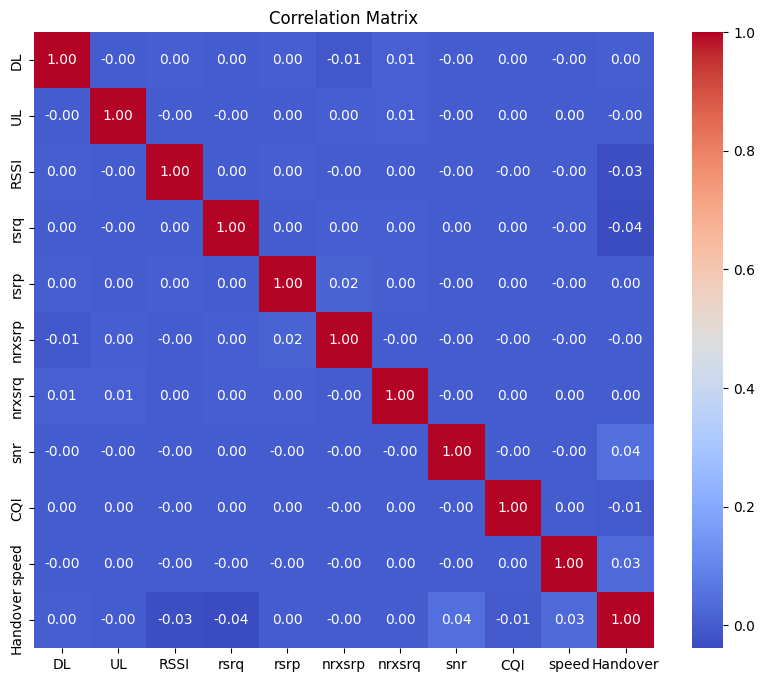

In [10]:
# Compute correlation matrix including target
corr_matrix = data[feature_cols + ['Handover']].corr()

# Show correlation of each feature with 'Handover'
handover_corr = corr_matrix['Handover'].drop('Handover')
print("\nCorrelation with 'Handover':")
print(handover_corr.sort_values(ascending=False))

# Optional: Plot heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


In [11]:
# Check if 'Handover' is accidentally in feature columns
print("'Handover' in features (should be False):", 'Handover' in wo_bw_features)


'Handover' in features (should be False): False


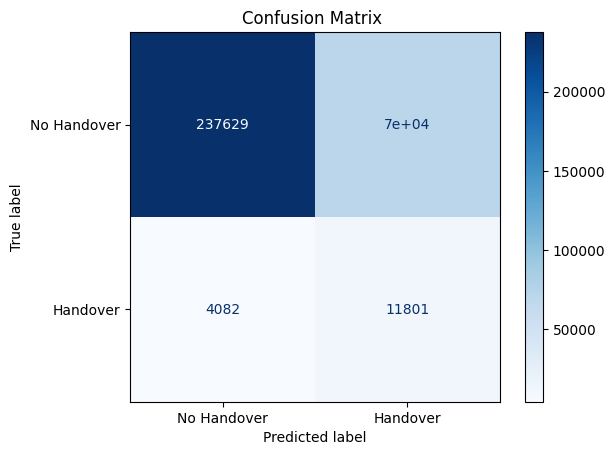

In [15]:
# Train model on w.o. BW
model_wo_bw = XGBClassifier(tree_method = "hist",device = "cuda",random_state=42, use_label_encoder=False, eval_metric='logloss')
model_wo_bw.fit(X_train_wo, y_train_wo)

# Predict
y_pred_wo = model_wo_bw.predict(X_test_wo)

# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_wo, y_pred_wo)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Handover', 'Handover'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix ")
plt.show()
